In [1]:
import numpy as np
from gensim.models import Word2Vec
import nltk
from nltk.tokenize import sent_tokenize, word_tokenize
from sklearn.model_selection import train_test_split
from collections import Counter

In [2]:
with open("../data/my_sweet_orange_tree.txt", "r", encoding="utf-8") as file:
    raw_text = file.read()

In [3]:
# tokenization

In [4]:
nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("wordnet")

[nltk_data] Downloading package punkt_tab to
[nltk_data]     /home/markjake/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /home/markjake/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /home/markjake/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [5]:
# Normalize curly apostrophes and quotation marks
raw_text = raw_text.replace("’", "'").replace("‘", "'")
raw_text = raw_text.replace("“", '"').replace("”", '"')


In [6]:
sentences = sent_tokenize(raw_text.lower())
tokenized_sentences = [word_tokenize(sentence) for sentence in sentences]

In [7]:
print(f"sentences size: {len(sentences)}")
print(f"token size: {len(tokenized_sentences)}")

sentences size: 4716
token size: 4716


In [8]:
train_sentences, temp_sentences = train_test_split(tokenized_sentences, test_size=0.2, random_state=42)

In [9]:
val_sentences, test_sentences = train_test_split(temp_sentences, test_size=0.5, random_state=42)

In [10]:
WINDOW_SIZE = 5
MIN_COUNT = 2
EMBED_SIZE = 100
HIDDEN1 = 256
HIDDEN2 = 256
KEEP_PROB = 0.7        # dropout: keep 70% of units (set 1.0 to turn off)
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.1
BATCH_SIZE = 128
MAX_EPOCHS = 40
PATIENCE = 3  

UNK_TOKEN = "<unk>"
train_counts = Counter(w for s in train_sentences for w in s)

vocab = [UNK_TOKEN] + [w for w, c in train_counts.most_common() if c >= MIN_COUNT]

word_to_idx = {w: i for i, w in enumerate(vocab)}
idx_to_word = {i: w for w, i in word_to_idx.items()}

unk_idx = word_to_idx[UNK_TOKEN]

VOCAB_SIZE = len(vocab)

PAD_IDX = VOCAB_SIZE   # extra all-zero embedding row used for padding

def to_unk(sentences):
    return [[w if w in word_to_idx else UNK_TOKEN for w in s] for s in sentences]

train_mapped = to_unk(train_sentences)
val_mapped = to_unk(val_sentences)
test_mapped = to_unk(test_sentences)

print("Vocabulary size:", VOCAB_SIZE)

Vocabulary size: 1823


In [11]:
print(f"train_sentences len: {len(train_sentences)}")
print(f"val_sentences len: {len(val_sentences)}")
print(f"test_sentences len: {len(test_sentences)}")

train_sentences len: 3772
val_sentences len: 472
test_sentences len: 472


In [14]:
WINDOW_SIZE = 3
def create_sequence(sentences, window_size=WINDOW_SIZE):
    pairs = []

    for sentence in sentences:
        for i in range(1, len(sentence)):
            context = sentence[max(0, i - window_size):i]
            target = sentence[i]
            pairs.append((context, target))

    return pairs


def context_to_vector(context, embedding_model):
    context = context[-WINDOW_SIZE:]

    vectors = []

    for word in context:
        if word in embedding_model.wv:
            vectors.append(embedding_model.wv[word])
        else:
            vectors.append(np.zeros(EMBED_SIZE, dtype=np.float32))

    # Pad missing context positions on the left
    while len(vectors) < WINDOW_SIZE:
        vectors.insert(
            0,
            np.zeros(EMBED_SIZE, dtype=np.float32)
        )

    return np.concatenate(vectors).astype(np.float32)

In [15]:
embedding_model = Word2Vec(
    sentences=train_mapped,
    vector_size=EMBED_SIZE,
    window=5,
    min_count=MIN_COUNT,
    sg=1,
    workers=4,
    epochs=10,
    seed=42
)
E = np.zeros((VOCAB_SIZE + 1, EMBED_SIZE), dtype=np.float32)
for word, idx in word_to_idx.items():
    E[idx] = embedding_model.wv[word]

In [16]:
# word_to_idx = {
#     word: idx
#     for idx, word in enumerate(embedding_model.wv.index_to_key)
# }

# idx_to_word = {
#     idx: word
#     for word, idx in word_to_idx.items()
# }

# UNK_TOKEN = "<unk>"

# if UNK_TOKEN not in word_to_idx:
#     unk_idx = len(word_to_idx)
#     word_to_idx[UNK_TOKEN] = unk_idx
#     idx_to_word[unk_idx] = UNK_TOKEN


# VOCAB_SIZE = len(word_to_idx)
# EMBED_SIZE = embedding_model.wv.vector_size

In [17]:
train_pairs = create_sequence(train_sentences)
val_pairs = create_sequence(val_sentences)
test_pairs = create_sequence(test_sentences)

print("Training pairs:", len(train_pairs))
print("Validation pairs:", len(val_pairs))
print("Test pairs:", len(test_pairs))

Training pairs: 39510
Validation pairs: 5037
Test pairs: 4922


In [18]:
def create_dataset(mapped_sentences):
    ctx_rows, targets = [], []
    for sentence in mapped_sentences:
        ids = [word_to_idx[word] for word in sentence]
        for i in range(1, len(ids)):
            ctx = ids[max(0, i - WINDOW_SIZE):i]
            ctx = [PAD_IDX] * (WINDOW_SIZE - len(ctx)) + ctx
            ctx_rows.append(ctx)
            targets.append(ids[i])
            
    ctx_idx = np.array(ctx_rows, dtype=np.int64)
    X = E[ctx_idx].reshape(len(ctx_idx), -1)
    
    return X, np.array(targets, dtype=np.int64)

In [19]:
X_train, y_train = create_dataset(train_mapped)
X_val, y_val = create_dataset(val_mapped)
X_test, y_test = create_dataset(test_mapped)

print(f"X_train: {X_train.shape}")
print(f"X_val: {X_val.shape}")
print(f"X_test: {X_test.shape}")
print(f"<unk> targets  train: {np.mean(y_train == unk_idx):.2%}  "
      f"val: {np.mean(y_val == unk_idx):.2%}  test: {np.mean(y_test == unk_idx):.2%}")

X_train: (39510, 300)
X_val: (5037, 300)
X_test: (4922, 300)
<unk> targets  train: 4.34%  val: 6.53%  test: 6.44%


In [20]:
# old
# def prepare_dataset(pairs, embedding_model, word_to_idx):
#     X = np.array([
#         context_to_vector(context, embedding_model)
#         for context, target in pairs
#     ], dtype=np.float32)
#     y = np.array([
#         word_to_idx.get(target, word_to_idx["<unk>"])
#         for _, target in pairs
#     ], dtype=np.int64)

#     return X, y
    

In [21]:
# X_train, y_train = prepare_dataset(train_pairs, embedding_model, word_to_idx)
# X_val, y_val = prepare_dataset(val_pairs, embedding_model, word_to_idx)
# X_test, y_test = prepare_dataset(test_pairs, embedding_model, word_to_idx)

In [22]:

print("Vocabulary size:", VOCAB_SIZE)
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("Training target range:", y_train.min(), y_train.max())
print("Validation target range:", y_val.min(), y_val.max())
print("Test target range:", y_test.min(), y_test.max())

print("Unknown validation targets:",
      np.sum(y_val == word_to_idx["<unk>"]))

print("Unknown test targets:",
      np.sum(y_test == word_to_idx["<unk>"]))


Vocabulary size: 1823
X_train: (39510, 300)
y_train: (39510,)
X_val: (5037, 300)
y_val: (5037,)
X_test: (4922, 300)
y_test: (4922,)
Training target range: 0 1822
Validation target range: 0 1819
Test target range: 0 1816
Unknown validation targets: 329
Unknown test targets: 317


In [23]:
unk_idx = word_to_idx["<unk>"]

print("Unknown token index:", unk_idx)
print("Vocabulary size:", VOCAB_SIZE)

assert y_train.min() >= 0
assert y_train.max() < VOCAB_SIZE

assert y_val.min() >= 0
assert y_val.max() < VOCAB_SIZE

assert y_test.min() >= 0
assert y_test.max() < VOCAB_SIZE

print("All target indices are valid.")

Unknown token index: 0
Vocabulary size: 1823
All target indices are valid.


In [24]:
def onehot(Y):
    return np.eye(len(word_to_idx))[Y]

In [25]:
# relu
def relu(Z):
    return np.maximum(0, Z)
# softmax
def softmax(Z):
    exp_z = np.exp(Z - np.max(Z, axis=1, keepdims=True))
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)

In [26]:
def initialize_parameters(
    input_size, hiddenLayer1_size, hiddenLayer2_size, output_size
):
    np.random.seed(42)

    parameters = {
        "w1": (np.random.randn(input_size, hiddenLayer1_size) * np.sqrt(2 / input_size)).astype(np.float32), # they call this he like hee-hee
        "b1": np.zeros((1, hiddenLayer1_size)).astype(np.float32),
        "w2": (np.random.randn(hiddenLayer1_size, hiddenLayer2_size) * np.sqrt(2 / hiddenLayer1_size)).astype(np.float32),
        "b2": np.zeros((1, hiddenLayer2_size)).astype(np.float32),
        "w3": (np.random.randn(hiddenLayer2_size, output_size) * np.sqrt(2 / hiddenLayer2_size)).astype(np.float32),
        "b3": np.zeros((1, output_size)).astype(np.float32),
    }

    return parameters

In [27]:
def dropout_mask(shape, keep_prob):
    return ((np.random.rand(*shape) < keep_prob) / keep_prob).astype(np.float32)

In [28]:
def forward_propagation(X, parameters, keep_prob=1.0):
    w1, b1, w2, b2, w3, b3 = (
        parameters["w1"],
        parameters["b1"],
        parameters["w2"],
        parameters["b2"],
        parameters["w3"],
        parameters["b3"],
    )

    # first layer
    Z1 = np.dot(X, w1) + b1
    A1 = relu(Z1)
    D1 = None
    if keep_prob < 1.0:
        D1 = dropout_mask(A1.shape, keep_prob)
        A1 = A1 * D1

    # second layer
    Z2 = np.dot(A1, w2) + b2
    A2 = relu(Z2)
    D2 = None
    if keep_prob < 1.0:
        D2 = dropout_mask(A2.shape, keep_prob)
        A2 = A2 * D2



    # output layer
    Z3 = np.dot(A2, w3) + b3
    A3 = softmax(Z3)

    cache = {
        "Z1": Z1,
        "A1": A1,
        "D1": D1,
        "Z2": Z2,
        "A2": A2,
        "D2": D2,
        "Z3": Z3,
        "A3": A3,
    }

    return A3, cache


In [29]:
def compute_cost(Y, A3):
    m = Y.shape[0]

    correct_prob = np.clip(A3[np.arange(m), Y], 1e-12, 1.0)

    L = -1 / m * np.sum(np.log(correct_prob))

    return L

In [245]:
# def backpropagation(w1, b1, w2, b2, w3, b3, cache, X, Y, alpha):
#     m = Y.shape[0]
#     Z1, A1, Z2, A2, Z3, A3 = cache["Z1"], cache["A1"], cache["Z2"], cache["A2"], cache["Z3"], cache["A3"]

#     # output layer
#     dZ3 = A3 - onehot(Y)
#     dW3 = np.dot(A2.T, dZ3) / m
#     db3 = np.sum(dZ3, axis=0, keepdims=True) / m

#     # second layer
#     dA2 = np.dot(dZ3, w3.T)
#     dZ2 = dA2 * (Z2 > 0) # relu'
#     db2 = np.sum(dZ2, axis=0, keepdims=True) / m
#     dW2 = np.dot(A1.T, dZ2) / m

#     # first layer
#     dA1 = np.dot(dZ2, w2.T)
#     dZ1 = dA1 * (Z1 > 0)
#     db1 = np.sum(dZ1, axis=0, keepdims=True) / m
#     dW1 = np.dot(X.T, dZ1) / m

#     return dW1, db1, dW2, db2, dW3, db3

In [30]:
def backpropagation(params, cache, X, Y):
    w1, b1, w2, b2, w3, b3 = params["w1"], params["b1"], params["w2"], params["b2"], params["w3"], params["b3"] 
    m = Y.shape[0]

    Z1, A1 = cache["Z1"], cache["A1"]
    Z2, A2 = cache["Z2"], cache["A2"]
    A3 = cache["A3"]

    # Output layer: softmax + cross-entropy
    # dZ3 = A3 - onehot(Y)
    dZ3 = A3.copy()
    dZ3[np.arange(len(Y)), Y] -= 1
    dW3 = A2.T @ dZ3 / m
    db3 = np.sum(dZ3, axis=0, keepdims=True) / m

    # Hidden layer 2: ReLU
    dA2 = dZ3 @ w3.T
    if cache["D2"] is not None:
        dA2 = dA2 * cache["D2"]
    dZ2 = dA2 * (Z2 > 0)
    dW2 = A1.T @ dZ2 / m
    db2 = np.sum(dZ2, axis=0, keepdims=True) / m

    # Hidden layer 1: ReLU
    dA1 = dZ2 @ w2.T
    if cache["D1"] is not None:
        dA1 = dA1 * cache["D1"]
    dZ1 = dA1 * (Z1 > 0)
    dW1 = X.T @ dZ1 / m
    db1 = np.sum(dZ1, axis=0, keepdims=True) / m

    # return dW1, db1, dW2, db2, dW3, db3
    return {"w1": dW1, "b1": db1, "w2": dW2, "b2": db2, "w3": dW3, "b3": db3}

In [31]:
def evaluate(X, y, params, batch_size=128):
    total_loss = 0.0
    total_correct = 0
    n = len(X)

    for start in range(0, n, batch_size):
        X_batch = X[start:start + batch_size]
        y_batch = y[start:start + batch_size]

        probs, _ = forward_propagation(X_batch, params)

        total_loss += compute_cost(y_batch, probs) * len(y_batch)
        total_correct += np.sum(
            np.argmax(probs, axis=1) == y_batch
        )

    return total_loss / n, total_correct / n

In [259]:
# input_size = embedding_model.wv.vector_size * 3
# hidden1_size = 128
# hidden2_size = 64
# output_size = len(embedding_model.wv.index_to_key)

# params = initialize_parameters(input_size, hidden1_size, hidden2_size, output_size)

In [260]:
# normal gradient
# alpha = 0.05
# costs = []
# for i in range(500):
#     A3, cache = forward_propagation(X, params)
#     cost = compute_cost(y, A3)
#     costs.append(cost)
#     dw1, db1, dw2, db2, dw3, db3 = backpropagation(params["w1"], params["b1"], params["w2"], params["b2"], params["w3"], params["b3"], cache, X, y, alpha)

#     # update params
#     params["w1"] -= alpha * dw1
#     params["b1"] -= alpha * db1
    
#     params["w2"] -= alpha * dw2
#     params["b2"] -= alpha * db2
    
#     params["w3"] -= alpha * dw3
#     params["b3"] -= alpha * db3

#     if i % 50 == 0:
#         print(f"epoch {i}, lost: {cost}")

In [261]:
# # gradient descent with velocity (momentum)
# # testing

# alpha = 0.05
# beta = 0.9

# v = {
#     "dw1": np.zeros_like(params["w1"]),
#     "db1": np.zeros_like(params["b1"]),
#     "dw2": np.zeros_like(params["w2"]),
#     "db2": np.zeros_like(params["b2"]),
#     "dw3": np.zeros_like(params["w3"]),
#     "db3": np.zeros_like(params["b3"]),
# }


# costs = []
# for i in range(500):
#     A3, cache = forward_propagation(X, params)
#     cost = compute_cost(y, A3)
#     costs.append(cost)
#     dw1, db1, dw2, db2, dw3, db3 = backpropagation(params["w1"], params["b1"], params["w2"], params["b2"], params["w3"], params["b3"], cache, X, y, alpha)


#     v["dw1"] = beta * v["dw1"] + (1 - beta) * dw1
#     v["db1"] = beta * v["db1"] + (1 - beta) * db1
#     v["dw2"] = beta * v["dw2"] + (1 - beta) * dw2
#     v["db2"] = beta * v["db2"] + (1 - beta) * db2
#     v["dw3"] = beta * v["dw3"] + (1 - beta) * dw3
#     v["db3"] = beta * v["db3"] + (1 - beta) * db3
#     # update params using velocity
#     params["w1"] -= alpha * v["dw1"]
#     params["b1"] -= alpha * v["db1"]
    
#     params["w2"] -= alpha * v["dw2"]
#     params["b2"] -= alpha * v["db2"]
    
#     params["w3"] -= alpha * v["dw3"]
#     params["b3"] -= alpha * v["db3"]

#     if i % 50 == 0:
#         print(f"epoch {i}, lost: {cost}")

In [262]:
# my potato machine can't handle the training

# import numpy as np

# # Start with fresh parameters
# params = initialize_parameters(
#     X_train.shape[1], 128, 128, len(word_to_idx)
# )
# print("X:", X_train.shape)
# print("w1:", params["w1"].shape)
# print("b1:", params["b1"].shape)
# print("w2:", params["w2"].shape)
# print("b2:", params["b2"].shape)
# print("w3:", params["w3"].shape)
# print("b3:", params["b3"].shape)


# # Adam settings
# learning_rate = 0.001
# beta1 = 0.9
# beta2 = 0.999
# epsilon = 1e-8
# weight_decay = 0.01

# keys = ["w1", "b1", "w2", "b2", "w3", "b3"]

# m = {k: np.zeros_like(params[k]) for k in keys}
# v = {k: np.zeros_like(params[k]) for k in keys}

# costs = []
# epochs = 1000

# for epoch in range(1, epochs + 1):
#     A3, cache = forward_propagation(X_train, params)
#     cost = compute_cost(y_train, A3)
#     costs.append(cost)

#     grads = backpropagation(
#         params["w1"], params["b1"],
#         params["w2"], params["b2"],
#         params["w3"], params["b3"],
#         cache, X_train, y_train
#     )

#     grads = dict(zip(keys, grads))

#     for k in keys:
#         m[k] = beta1 * m[k] + (1 - beta1) * grads[k]
#         v[k] = beta2 * v[k] + (1 - beta2) * grads[k]**2

#         m_hat = m[k] / (1 - beta1**epoch)
#         v_hat = v[k] / (1 - beta2**epoch)

#         # adaptive learning rate
#         # params[k] -= learning_rate * m_hat / (
#         #     np.sqrt(v_hat) + epsilon
#         # )
#         # apply weight decay only on weights matrices
#         if k in ["w1", "w2", "w3"]:
#             params[k] *= (1 - learning_rate * weight_decay)
            
#         params[k] -= learning_rate * m_hat / (
#             np.sqrt(v_hat) + epsilon
#         )
        

#     if epoch == 1 or epoch % 100 == 0:
#         print(f"Epoch {epoch}: loss = {cost:.4f}")

# # # Evaluate training accuracy
# # A3, _ = forward_propagation(X, params)
# # predictions = np.argmax(A3, axis=1)

# # print("Training accuracy:", np.mean(predictions == y))

# # unique, counts = np.unique(predictions, return_counts=True)
# # top = np.argsort(counts)[::-1][:10]

# # print("\nMost predicted words:")
# # for i in top:
# #     idx = unique[i]
# #     print(f"{idx_to_word[idx]}: {counts[i]} ({counts[i]/len(y):.1%})")

In [215]:
params = initialize_parameters(
    X_train.shape[1], HIDDEN1, HIDDEN2, VOCAB_SIZE
)

print("X:", X_train.shape)
print("w1:", params["w1"].shape)
print("b1:", params["b1"].shape)
print("w2:", params["w2"].shape)
print("b2:", params["b2"].shape)
print("w3:", params["w3"].shape)
print("b3:", params["b3"].shape)

learning_rate = 0.001
beta1 = 0.9
beta2 = 0.999
epsilon = 1e-8
weight_decay = 0.01

keys = ["w1", "b1", "w2", "b2", "w3", "b3"]

m_adam = {k: np.zeros_like(params[k]) for k in keys}
v_adam = {k: np.zeros_like(params[k]) for k in keys}

epochs = MAX_EPOCHS
batch_size = 128
step = 0

## costsststs
costs = []
train_losses, val_losses, val_accs = [], [], []

for epoch in range(1, epochs + 1):
    # shuffle training examples each epoch
    indices = np.random.permutation(len(X_train))

    epoch_loss = 0.0

    for start in range(0, len(X_train), batch_size):
        batch_idx = indices[start:start + batch_size]

        X_batch = X_train[batch_idx]
        y_batch = y_train[batch_idx]

        # Forward propagation
        A3, cache = forward_propagation(X_batch, params, KEEP_PROB)

        batch_loss = compute_cost(y_batch, A3)
        epoch_loss += batch_loss * len(batch_idx)

        # Backpropagation
        grads = backpropagation(
            params["w1"], params["b1"],
            params["w2"], params["b2"],
            params["w3"], params["b3"],
            cache, X_batch, y_batch
        )

        grads = dict(zip(keys, grads))
        step += 1

        # Adam update
        for k in keys:
            g = grads[k]

            m_adam[k] = beta1 * m_adam[k] + (1 - beta1) * g
            v_adam[k] = beta2 * v_adam[k] + (1 - beta2) * (g ** 2)

            m_hat = m_adam[k] / (1 - beta1 ** step)
            v_hat = v_adam[k] / (1 - beta2 ** step)

            # Decay weights, not biases
            if k in ["w1", "w2", "w3"]:
                params[k] *= (1 - learning_rate * weight_decay)

            params[k] -= learning_rate * m_hat / (
                np.sqrt(v_hat) + epsilon
            )

    avg_loss = epoch_loss / len(X_train)
    costs.append(avg_loss)

    print(f"Epoch {epoch}: loss = {avg_loss:.4f}")

X: (39510, 300)
w1: (300, 256)
b1: (1, 256)
w2: (256, 256)
b2: (1, 256)
w3: (256, 1823)
b3: (1, 1823)


KeyError: 'dA1'

In [32]:
params = initialize_parameters(X_train.shape[1], HIDDEN1, HIDDEN2, VOCAB_SIZE)
keys = list(params.keys())
m_adam = {k: np.zeros_like(v) for k, v in params.items()}
v_adam = {k: np.zeros_like(v) for k, v in params.items()}
beta1, beta2, eps = 0.9, 0.999, 1e-8

train_losses, val_losses, val_accs = [], [], []
best_val, best_params, bad_epochs, step = np.inf, None, 0, 0

for epoch in range(1, MAX_EPOCHS + 1):
    order = np.random.permutation(len(X_train))
    for start in range(0, len(X_train), BATCH_SIZE):
        b = order[start:start + BATCH_SIZE]
        Xb, yb = X_train[b], y_train[b]

        A3, cache = forward_propagation(Xb, params, KEEP_PROB)
        grads = backpropagation(params, cache, Xb, yb)

        step += 1
        for k in keys:
            m_adam[k] = beta1 * m_adam[k] + (1 - beta1) * grads[k]
            v_adam[k] = beta2 * v_adam[k] + (1 - beta2) * grads[k] ** 2
            m_hat = m_adam[k] / (1 - beta1 ** step)
            v_hat = v_adam[k] / (1 - beta2 ** step)
            if k.startswith("w"):                      # decay weights, not biases!
                params[k] *= (1 - LEARNING_RATE * WEIGHT_DECAY)
            params[k] -= LEARNING_RATE * m_hat / (np.sqrt(v_hat) + eps)

    # evaluate WITHOUT dropout so train/val numbers are comparable
    tr_loss, tr_acc = evaluate(X_train, y_train, params)
    va_loss, va_acc = evaluate(X_val, y_val, params)
    train_losses.append(tr_loss); val_losses.append(va_loss); val_accs.append(va_acc)
    print(f"Epoch {epoch:2d} | train loss {tr_loss:.3f} acc {tr_acc:.3f} "
          f"| val loss {va_loss:.3f} acc {va_acc:.3f}")

    if va_loss < best_val:
        best_val, bad_epochs = va_loss, 0
        best_params = {k: v.copy() for k, v in params.items()}
    else:
        bad_epochs += 1
        if bad_epochs >= PATIENCE:
            print(f"Early stopping: no improvement for {PATIENCE} epochs.")
            break

params = best_params
print(f"Restored best weights (val loss {best_val:.3f})")

Epoch  1 | train loss 4.816 acc 0.171 | val loss 4.750 acc 0.176
Epoch  2 | train loss 4.528 acc 0.187 | val loss 4.513 acc 0.192
Epoch  3 | train loss 4.373 acc 0.194 | val loss 4.414 acc 0.198
Epoch  4 | train loss 4.264 acc 0.198 | val loss 4.360 acc 0.202
Epoch  5 | train loss 4.174 acc 0.200 | val loss 4.330 acc 0.206
Epoch  6 | train loss 4.086 acc 0.205 | val loss 4.294 acc 0.206
Epoch  7 | train loss 4.024 acc 0.207 | val loss 4.282 acc 0.209
Epoch  8 | train loss 3.947 acc 0.208 | val loss 4.266 acc 0.209
Epoch  9 | train loss 3.890 acc 0.214 | val loss 4.258 acc 0.211
Epoch 10 | train loss 3.838 acc 0.216 | val loss 4.263 acc 0.214
Epoch 11 | train loss 3.798 acc 0.217 | val loss 4.272 acc 0.216
Epoch 12 | train loss 3.731 acc 0.221 | val loss 4.264 acc 0.216
Early stopping: no improvement for 3 epochs.
Restored best weights (val loss 4.258)


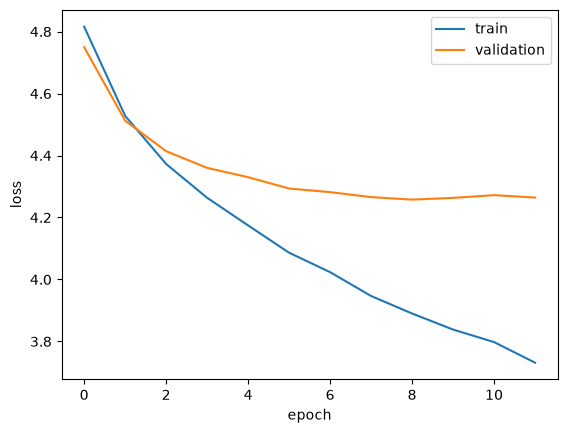

train loss 3.890 acc 0.214 | excluding <unk>: loss 3.941 acc 0.206
val   loss 4.258 acc 0.211 | excluding <unk>: loss 4.359 acc 0.199
test  loss 4.248 acc 0.212 | excluding <unk>: loss 4.349 acc 0.199


In [33]:
import matplotlib.pyplot as plt

plt.plot(train_losses, label="train")
plt.plot(val_losses, label="validation")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.show()

for name, X_, y_ in [("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
    loss, acc = evaluate(X_, y_, params)
    known = y_ != unk_idx
    k_loss, k_acc = evaluate(X_[known], y_[known], params)
    print(f"{name:5s} loss {loss:.3f} acc {acc:.3f} | excluding <unk>: loss {k_loss:.3f} acc {k_acc:.3f}")

In [34]:
def context_to_input(words):
    ids = [word_to_idx.get(w, unk_idx) for w in words][-WINDOW_SIZE:]
    ids = [PAD_IDX] * (WINDOW_SIZE - len(ids)) + ids
    return E[ids].reshape(1, -1)

def next_word_probs(words):
    probs, _ = forward_propagation(context_to_input(words), params)
    return probs[0]

def show_top_predictions(context, top_n=5):
    words = context.lower().split()
    probs = next_word_probs(words)
    print(f"\nContext: {context}")
    for idx in np.argsort(probs)[::-1][:top_n]:
        print(f"{idx_to_word[idx]:<12} {probs[idx]:.4f}")

def generate_text(start_text, num_words=50, temperature=0.8, top_k=20):
    words = start_text.lower().split()
    for _ in range(num_words):
        probs = next_word_probs(words[-WINDOW_SIZE:]).astype(np.float64)
        probs[unk_idx] = 0.0                              # never emit <unk>
        top = np.argsort(probs)[::-1][:top_k]             # keep only top-k words
        p = probs[top] ** (1.0 / temperature)
        p /= p.sum()
        words.append(idx_to_word[int(np.random.choice(top, p=p))])
    return " ".join(words)

show_top_predictions("the")
show_top_predictions("he was")
show_top_predictions("it was a")
print()
print(generate_text("it was a", 50))


Context: the
<unk>        0.0985
portuguese   0.0353
car          0.0320
first        0.0262
other        0.0259

Context: he was
a            0.0714
n't          0.0706
<unk>        0.0569
so           0.0558
the          0.0428

Context: it was a
<unk>        0.1486
little       0.0554
good         0.0495
bit          0.0432
big          0.0241

it was a big beautiful , ' is you 'll be your parents ! '' ! ' ? '' you were you going on a few and we went to be , not to the first , she 'd have come back me in the street . ' cause , then i had


In [267]:
A3_val, _ = forward_propagation(X_val, params)
val_pred = np.argmax(A3_val, axis=1)

print("Validation accuracy:", np.mean(val_pred == y_val) * 100)
print("Validation loss:", compute_cost(y_val, A3_val))
print()

A3_train, _ = forward_propagation(X_train, params)
train_pred = np.argmax(A3_train, axis=1)

print("train accuracy:", np.mean(train_pred == y_train) * 100)
print("train loss:", compute_cost(y_train, A3_train))
print()

A3_test, _ = forward_propagation(X_test, params)
test_pred = np.argmax(A3_test, axis=1)

print("test accuracy:", np.mean(test_pred == y_test) * 100)
print("test loss:", compute_cost(y_test, A3_test))

Validation accuracy: 21.30236251737145
Validation loss: 4.27327

train accuracy: 21.40470766894457
train loss: 3.8841321

test accuracy: 21.17025599349858
test loss: 4.2514024


In [268]:
def predict_next_word(context):
    context = context.lower().split()

    if not context:
        raise ValueError("Provide at least one context word.")

    # Check that all context words exist in the vocabulary
    unknown = [word for word in context if word not in word_to_idx]
    if unknown:
        raise ValueError(f"Unknown vocabulary words: {unknown}")

    x = context_to_vector(context, embedding_model).reshape(1, -1)
    probabilities, _ = forward_propagation(x, params)

    predicted_idx = int(np.argmax(probabilities[0]))
    return idx_to_word[predicted_idx]


# print(predict_next_word("sometimes"))
# print(predict_next_word("he was"))
# print(predict_next_word("it was a"))

i
a
<unk>


In [271]:
def generate_text(start_text, num_words=50):
    words = start_text.lower().split()

    for _ in range(num_words):
        context = words[-3:]
        next_word = predict_next_word(" ".join(context))
        words.append(next_word)

    return " ".join(words)

print(generate_text("zezé", 30))

zezé , i 'm going to be a <unk> . ' cause , zezé . ' cause , zezé . ' cause , zezé . ' cause , zezé . '
